# 00 — Master data check and preprocessing

## 1. Purpose and setup
Prepare participant-level relative EEG band power for later NSCI 270 notebooks. Task 1 (`ds003944`, version 1.0.1) is the intended training set; Task 2 (`ds003947`, version 1.0.1) is the intended test set. This notebook checks both datasets and applies one fixed, diagnosis-blind procedure. It does not fit models or use diagnosis-related feature patterns to make decisions.

Run all cells in order using the project's `.venv` Python kernel (`pip install -r requirements.txt`). Source files stay in `data/resting-task-1` and `data/resting-task-2`; small derived outputs go to `outputs/master_preprocessing`. One recording is processed at a time.

**Interpretation limits:** the generic header names are mapped by the order of `channels.tsv`, following BIDS. EEG units are microvolts in those tables and MNE's default for this EEGLAB export. These are documented conventions, not independently recovered acquisition records. Auxiliary-channel labels disagree between files; auxiliary channels and mastoids are excluded. Missing marker files mean no event/bad-interval history is available, not proof that the recordings are artifact-free.

In [1]:
from pathlib import Path
from configparser import ConfigParser
from importlib.metadata import version
import hashlib
import json
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch
import mne
from IPython.display import display, Markdown

# The notebook lives at the project root; this also works from a subfolder.
PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "data/resting-task-1").is_dir()
                and (p / "data/resting-task-2").is_dir()), None)
if PROJECT is None:
    raise FileNotFoundError("Open this notebook inside the nsci270-final project.")
OUTPUT = PROJECT / "outputs/master_preprocessing"
OUTPUT.mkdir(parents=True, exist_ok=True)
DATASETS = {
    "resting-task-1": {"accession": "ds003944", "version": "1.0.1", "role": "train"},
    "resting-task-2": {"accession": "ds003947", "version": "1.0.1", "role": "test"},
}
MOVED = ["sub-2140A", "sub-2170A", "sub-2174A", "sub-2176A", "sub-2177A",
         "sub-2184A", "sub-2193A", "sub-2214A", "sub-2217A", "sub-2221A"]
LABELS = {"Control": "Control", "Psychosis": "First Episode Psychosis"}
SETTINGS = {
    "maximum_input_seconds": 300.0,
    "filter_hz": [0.5, 40.0],
    "filter_method": "4th-order Butterworth, zero-phase forward/backward, SOS",
    "sampling_hz": 200.0,
    "edge_trim_seconds": 2.0,
    "epoch_seconds": 4.0,
    "reject_peak_to_peak_uv": 200.0,
    "reject_flat_peak_to_peak_uv": 1.0,
    "minimum_usable_seconds": 60.0,
    "welch_window_seconds": 2.0,
    "welch_overlap_fraction": 0.5,
    "bands_hz": {"delta": [1, 4], "theta": [4, 8], "alpha": [8, 13], "beta": [13, 30]},
    "total_power_hz": [1, 30],
    "isolated_bad_channel_rule": {
        "minimum_failed_epoch_fraction": 0.9,
        "minimum_ratio_to_median_channel_peak_to_peak": 5.0,
        "maximum_absolute_correlation_with_any_channel": 0.4,
        "maximum_channels_omitted": 1,
        "action": "omit from average reference, epoch screening, and channel-averaged features; no interpolation",
    },
    "reference": "average of the retained shared scalp channels (49, or 48 if one isolated bad channel is omitted)",
    "channel_mapping": "ordered first 60 channels.tsv rows; case normalized to uppercase",
    "units": "microV from channels.tsv; MNE default unit and resolution for EEGLAB export",
    "multiple_recordings": "exclude pending a study-specific aggregation decision",
}
mne.set_log_level("ERROR")
pd.set_option("display.max_colwidth", 100)
print("Project:", PROJECT)
print("Python:", platform.python_version(), "MNE:", mne.__version__)

Project: /Users/akhil/Documents/nsci270-final
Python: 3.14.7 MNE: 1.13.2


## 2. Data completeness and participant inventory
An EEG recording needs its binary `.eeg`, header `.vhdr`, recording JSON, and channel table. Check materialized contents, dimensions, diagnosis definitions, and the participant roster. Marker files are inspected when referenced; their absence in these continuous EEGLAB exports is reported separately. A participant with missing or multiple recordings stays in the inventory and receives an explicit reason.

The accession and version are checked against `dataset_description.json`. Acquisition membership comes from the dataset READMEs, not from guessing what an ID suffix means.

In [2]:
def file_problem(path):
    if path.is_symlink() and not path.exists():
        return "unmaterialized annex symlink"
    if not path.is_file():
        return "missing file"
    with path.open("rb") as handle:
        prefix = handle.read(200)
    if prefix.startswith(b"version https://git-lfs.github.com/spec/v1"):
        return "unmaterialized Git LFS pointer"
    if prefix.startswith((b"/annex/objects/", b".git/annex/", b"../.git/annex/")):
        return "unmaterialized annex pointer"
    if path.stat().st_size == 0:
        return "empty file"
    return ""


def read_header(path):
    text = path.read_text(encoding="utf-8-sig")
    header = ConfigParser(interpolation=None, strict=False)
    header.read_string(text[text.index("[Common Infos]"):])
    return header


records, participants, document_checks = [], [], []
channel_tables, headers, recording_metadata, readmes = {}, {}, {}, {}
for dataset, spec in DATASETS.items():
    folder = PROJECT / "data" / dataset
    required_docs = ["participants.tsv", "participants.json", "dataset_description.json", "README"]
    doc_problems = [f"{name}: {file_problem(folder / name)}" for name in required_docs
                    if file_problem(folder / name)]
    if doc_problems:
        raise FileNotFoundError(f"{dataset}: " + "; ".join(doc_problems))
    roster = pd.read_csv(folder / "participants.tsv", sep="\t", dtype=str)
    labels = json.loads((folder / "participants.json").read_text())["type"]["Levels"]
    description = json.loads((folder / "dataset_description.json").read_text())
    readmes[dataset] = (folder / "README").read_text()
    expected_doi = f"doi:10.18112/openneuro.{spec['accession']}.v{spec['version']}"
    document_checks.append({"dataset": dataset,
        "doi_matches": description.get("DatasetDOI") == expected_doi,
        "label_mapping_matches": labels.get("Control") == "Healthy"
                                  and labels.get("Psychosis") == "First Episode Psychosis",
        "duplicate_roster_ids": int(roster.participant_id.duplicated().sum())})
    for participant_id in sorted(set(roster.participant_id) |
                                 {p.name for p in folder.glob("sub-*") if p.is_dir()}):
        rows = roster.loc[roster.participant_id == participant_id]
        diagnosis = rows.iloc[0]["type"] if len(rows) == 1 else "unknown"
        acquisition = (2 if dataset == "resting-task-2" or participant_id in MOVED else 1)
        participant = {"dataset": dataset, "accession": spec["accession"],
                       "participant_id": participant_id, "diagnosis": diagnosis,
                       "acquisition": acquisition, "roster_rows": len(rows)}
        participants.append(participant)
        # Union catches a binary file or sidecar whose header is missing.
        stems = sorted({str(p.with_suffix("")) for p in (folder / participant_id).rglob("*_eeg.*")
                        if p.suffix in {".eeg", ".vhdr", ".json"}})
        for stem in stems:
            header_path = Path(stem + ".vhdr")
            paths = {"header_path": header_path, "eeg_path": Path(stem + ".eeg"),
                     "json_path": Path(stem + ".json"),
                     "channels_path": Path(stem.removesuffix("_eeg") + "_channels.tsv")}
            recording_id = str(header_path.relative_to(PROJECT))
            row = {**participant, "recording_id": recording_id,
                   **{key: str(path.relative_to(PROJECT)) for key, path in paths.items()}}
            problems = [f"{key}: {file_problem(path)}" for key, path in paths.items()
                        if file_problem(path)]
            try:
                if not problems:
                    header = read_header(header_path)
                    meta = json.loads(paths["json_path"].read_text())
                    channels = pd.read_csv(paths["channels_path"], sep="\t", keep_default_na=False)
                    common = header["Common Infos"]
                    n_channels, n_samples = int(common["NumberOfChannels"]), int(common["DataPoints"])
                    sfreq = 1e6 / float(common["SamplingInterval"])
                    names = [header["Channel Infos"][f"Ch{i+1}"].split(",")[0]
                             for i in range(n_channels)]
                    marker = common.get("MarkerFile", "")
                    if marker and file_problem(header_path.parent / marker):
                        problems.append("referenced marker file: " + file_problem(header_path.parent / marker))
                    if (header_path.parent / common["DataFile"]).resolve() != paths["eeg_path"].resolve():
                        problems.append("header DataFile does not match binary path")
                    if common.get("DataOrientation") != "VECTORIZED" or header["Binary Infos"]["BinaryFormat"] != "IEEE_FLOAT_32":
                        problems.append("unexpected binary layout; review before processing")
                    if paths["eeg_path"].stat().st_size != n_channels * n_samples * 4:
                        problems.append("binary size does not match header dimensions")
                    if len(channels) != n_channels or channels.name.str.upper().duplicated().any():
                        problems.append("channel count mismatch or duplicate names")
                    if n_channels != 64 or not channels.iloc[:60].type.eq("EEG").all():
                        problems.append("unexpected scalp/auxiliary layout")
                    if not channels.iloc[:60].units.eq("microV").all():
                        problems.append("unexpected scalp EEG units")
                    if any(not name.startswith("EEG") for name in names[:60]):
                        problems.append("non-EEG header label within proposed scalp channels")
                    if not np.isclose(sfreq, meta["SamplingFrequency"], rtol=1e-6):
                        problems.append("sampling rates disagree")
                    if not np.isclose(n_samples / sfreq, meta["RecordingDuration"], atol=1/sfreq):
                        problems.append("durations disagree")
                    if str(meta.get("TaskName", "")).lower() != "rest":
                        problems.append("unexpected task")
                    row.update(task=meta.get("TaskName"), sampling_hz=sfreq,
                               duration_seconds=n_samples/sfreq, n_channels=n_channels,
                               reference=meta.get("EEGReference", "unknown"),
                               software_filters=str(meta.get("SoftwareFilters", "not documented")),
                               hardware_filters=str(meta.get("HardwareFilters", "not documented")),
                               instructions=meta.get("Instructions", "not documented"),
                               marker_file_present=bool(marker),
                               bad_channel_status_available="status" in channels.columns,
                               header_labels_match_table=names == channels.name.tolist())
                    headers[recording_id], channel_tables[recording_id] = header, channels
                    recording_metadata[recording_id] = meta
            except (OSError, ValueError, KeyError) as error:
                problems.append(f"metadata unreadable: {error}")
            row["completeness_reason"] = "; ".join(problems)
            records.append(row)

inventory = pd.DataFrame(records)
participant_inventory = pd.DataFrame(participants)
document_checks = pd.DataFrame(document_checks)
counts = inventory.groupby(["dataset", "participant_id"]).size().rename("n_recordings")
participant_inventory = participant_inventory.merge(counts, on=["dataset", "participant_id"], how="left")
participant_inventory["n_recordings"] = participant_inventory.n_recordings.fillna(0).astype(int)
display(document_checks)
display(participant_inventory.groupby(["dataset", "diagnosis"]).size().rename("participants").to_frame())
display(participant_inventory.loc[participant_inventory.n_recordings != 1])
print("Recordings with completeness problems:", int(inventory.completeness_reason.ne("").sum()))

,dataset,doi_matches,label_mapping_matches,duplicate_roster_ids
0,resting-task-1,True,True,0
1,resting-task-2,True,True,0


participants
dataset        diagnosis              
resting-task-1 Control              32
               Psychosis            50
resting-task-2 Control              30
               Psychosis            31

,dataset,accession,participant_id,diagnosis,acquisition,roster_rows,n_recordings


Recordings with completeness problems: 0


## 3. Independence and compatibility
The READMEs describe two independently collected samples. However, Task 1 includes ten people from acquisition 2. Dataset membership is therefore not the same as acquisition membership. No shared IDs or identical files is useful evidence, but cannot prove that differently named IDs represent different people. Later work should describe the test set as a **held-out dataset with unresolved person-level independence**, unless a crosswalk or author confirmation becomes available.

Both JSON sets describe eyes-open fixation and a TP9 reference. `SoftwareFilters: n/a` and absent hardware-filter history do not prove that no filtering occurred before export. The headers identify EEGLAB export, not a complete processing history.

For spatial comparability, use the intersection of the first 60 scalp EEG labels after case normalization. Exclude mastoids/reference sites and all four trailing auxiliary channels. No electrode coordinate files are supplied, so channels are never interpolated. The only per-recording change to this set is the fixed isolated-bad-channel omission described in Section 5 (at most one channel). The remaining channel-order assumption is recorded in every feature row.

Sources: local READMEs, recording JSON, channel tables, and [BIDS channel-table ordering](https://bids-specification.readthedocs.io/en/v1.7.0/04-modality-specific-files/03-electroencephalography.html). [EEGLAB's exporter](https://github.com/sccn/bva-io/blob/master/pop_writebva.m) writes float32 channel-major data and blank calibration fields; [MNE's reader](https://mne.tools/stable/generated/mne.io.read_raw_brainvision.html) uses microvolts by default. These conventions explain how the export is read; they do not independently verify electrode placement.

In [3]:
id_sets = {d: set(participant_inventory.loc[participant_inventory.dataset == d, "participant_id"])
           for d in DATASETS}
overlap = sorted(set.intersection(*id_sets.values()))
placement = pd.DataFrame({"participant_id": MOVED})
placement["in_task_1_roster"] = placement.participant_id.isin(id_sets["resting-task-1"])
placement["in_task_2_roster"] = placement.participant_id.isin(id_sets["resting-task-2"])
for d, label in [("resting-task-1", "task_1"), ("resting-task-2", "task_2")]:
    present = set(inventory.loc[inventory.dataset == d, "participant_id"])
    placement[f"in_{label}_files"] = placement.participant_id.isin(present)
placement["documented_in_both_readmes"] = placement.participant_id.map(
    lambda pid: all(pid in text for text in readmes.values()))
placement["correct_placement"] = (placement.in_task_1_roster & placement.in_task_1_files &
    ~placement.in_task_2_roster & ~placement.in_task_2_files & placement.documented_in_both_readmes)
scalp_sets = [set(table.iloc[:60].name.str.upper()) - {"M1", "M2", "TP9", "TP10"}
              for key, table in channel_tables.items()
              if inventory.set_index("recording_id").loc[key, "completeness_reason"] == ""]
shared_channels = sorted(set.intersection(*scalp_sets)) if scalp_sets else []
SETTINGS["shared_channels"] = shared_channels
compatibility = inventory.groupby("dataset").agg(
    recordings=("recording_id", "size"),
    sampling_rates=("sampling_hz", lambda x: sorted(x.dropna().unique().tolist())),
    duration_min=("duration_seconds", "min"), duration_max=("duration_seconds", "max"),
    references=("reference", lambda x: sorted(x.dropna().unique().tolist())),
    software_filters=("software_filters", lambda x: sorted(x.dropna().unique().tolist())),
    hardware_filters=("hardware_filters", lambda x: sorted(x.dropna().unique().tolist())))
display(placement)
display(compatibility)
print("Shared IDs:", overlap)
print(f"Shared scalp channels ({len(shared_channels)}):", ", ".join(shared_channels))
print("Same documented instructions:", inventory.instructions.nunique() == 1)
print("Scalp channels by dataset:", {d: sorted(next(t for k, t in channel_tables.items()
      if f"/{d}/" in k).iloc[:60].name.str.upper().tolist()) for d in DATASETS})
global_blockers = []
if not document_checks.doi_matches.all() or not document_checks.label_mapping_matches.all():
    global_blockers.append("Dataset version or diagnosis mapping mismatch")
if overlap:
    global_blockers.append("Shared participant IDs between datasets")
if not placement.correct_placement.all():
    global_blockers.append("Documented transferred-participant placement does not match files")
if not shared_channels:
    global_blockers.append("No verified metadata intersection of scalp channels")

,participant_id,in_task_1_roster,in_task_2_roster,in_task_1_files,in_task_2_files,documented_in_both_readmes,correct_placement
0,sub-2140A,True,False,True,False,True,True
1,sub-2170A,True,False,True,False,True,True
2,sub-2174A,True,False,True,False,True,True
3,sub-2176A,True,False,True,False,True,True
4,sub-2177A,True,False,True,False,True,True
5,sub-2184A,True,False,True,False,True,True
6,sub-2193A,True,False,True,False,True,True
7,sub-2214A,True,False,True,False,True,True
8,sub-2217A,True,False,True,False,True,True
9,sub-2221A,True,False,True,False,True,True


,recordings,sampling_rates,duration_min,duration_max,references,software_filters,hardware_filters
dataset,,,,,,,
resting-task-1,82,"[1000.0, 3000.0003]",300.0,397.000000,[TP9],[n/a],[not documented]
resting-task-2,61,"[1000.0, 3000.0003]",300.0,368.499963,[TP9],[n/a],[not documented]


Shared IDs: []
Shared scalp channels (49): AF3, AF4, AF7, C1, C2, C3, C4, C5, C6, CP1, CP2, CP3, CP4, CZ, F1, F2, F3, F4, F5, F6, F7, F8, FC1, FC2, FC5, FC6, FP1, FP2, FT7, FT8, FZ, O1, O2, OZ, P3, P4, P5, P6, P7, P8, PO3, PO4, PO7, PO8, PZ, T7, T8, TP7, TP8
Same documented instructions: True
Scalp channels by dataset: {'resting-task-1': ['AF3', 'AF4', 'AF6', 'AF7', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'CP1', 'CP2', 'CP3', 'CP4', 'CZ', 'F1', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7', 'F8', 'FC1', 'FC2', 'FC5', 'FC6', 'FP1', 'FP2', 'FPZ', 'FT10', 'FT7', 'FT8', 'FT9', 'FZ', 'IZ', 'O1', 'O2', 'OZ', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'PO3', 'PO4', 'PO7', 'PO8', 'PZ', 'T10', 'T7', 'T8', 'T9', 'TP10', 'TP7', 'TP8', 'TP9'], 'resting-task-2': ['AF3', 'AF4', 'AF7', 'AF8', 'AFZ', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'CP1', 'CP2', 'CP3', 'CP4', 'CP5', 'CP6', 'CZ', 'F1', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7', 'F8', 'FC1', 'FC2', 'FC3', 'FC4', 'FC5', 'FC6', 'FCZ', 'FP1', 'FP2', 'FT7', 'FT8', 'FZ',

## 4. Raw-data quality checks
Use MNE's standard BrainVision reader without changing source headers. Rename only the 60 scalp rows using the ordered channel table, then select the shared scalp channels. Check every sample of those channels for nonfinite values and whole-recording flat signals. Compute SHA-256 hashes to catch identical recordings stored under different IDs. Check stored bad-channel status when available; absence of status/markers is recorded as **unavailable**, not “all good.”

Fixed rules: exclude unreadable/incomplete recordings, unknown labels, ambiguous participant rows, duplicate files, multiple recordings pending an aggregation decision, annotated bad shared channels, nonfinite shared-channel samples, or a whole-recording constant shared channel. Later, reject any 4-second epoch with peak-to-peak amplitude above 200 µV or below 1 µV on any shared channel (both before and after average referencing). Require at least 60 seconds retained. These are conservative project choices, fixed before looking at group feature patterns; they are not clinical standards. One isolated, persistently bad channel may be omitted per recording (Section 5). No channel interpolation or ICA is used.

The first readable recording in sorted order from each dataset supplies the only representative raw plots. They are selected without diagnosis. Amplitudes use the documented microvolt convention.

In [4]:
def read_recording(row):
    raw = mne.io.read_raw_brainvision(PROJECT / row["header_path"], preload=False, verbose=False)
    table = channel_tables[row["recording_id"]]
    mapping = dict(zip(raw.ch_names[:60], table.iloc[:60].name.str.upper()))
    raw.rename_channels(mapping)
    raw.pick(shared_channels)
    raw.reorder_channels(shared_channels)
    if "status" in table:
        bad_names = set(table.loc[table.status.str.lower() == "bad", "name"].str.upper())
        raw.info["bads"] = sorted(bad_names & set(shared_channels))
    return raw


raw_checks, examples = [], {}
for row in inventory.to_dict("records"):
    result = {"recording_id": row["recording_id"], "raw_qc_reason": "",
              "readable": False, "sha256": "", "nonfinite_samples": 0,
              "flat_channels": "", "annotated_bad_channels": "", "reader_warnings": ""}
    if row["completeness_reason"]:
        result["raw_qc_reason"] = row["completeness_reason"]
    else:
        try:
            with (PROJECT / row["eeg_path"]).open("rb") as handle:
                result["sha256"] = hashlib.file_digest(handle, "sha256").hexdigest()
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                raw = read_recording(row)
                minima = np.full(len(shared_channels), np.inf)
                maxima = np.full(len(shared_channels), -np.inf)
                step = int(round(raw.info["sfreq"] * 10))
                for start in range(0, raw.n_times, step):
                    data = raw.get_data(start=start, stop=min(start + step, raw.n_times))
                    finite = np.isfinite(data)
                    result["nonfinite_samples"] += int((~finite).sum())
                    minima = np.minimum(minima, np.where(finite, data, np.inf).min(axis=1))
                    maxima = np.maximum(maxima, np.where(finite, data, -np.inf).max(axis=1))
                result.update(readable=True, actual_duration_seconds=raw.n_times/raw.info["sfreq"],
                              flat_channels=";".join(np.array(shared_channels)[maxima == minima]),
                              annotated_bad_channels=";".join(raw.info["bads"]),
                              max_raw_peak_to_peak_uv=float((maxima-minima).max()*1e6),
                              annotation_count=len(raw.annotations))
                reasons = []
                if result["nonfinite_samples"]: reasons.append("nonfinite samples in shared scalp channels")
                if result["flat_channels"]: reasons.append("constant shared scalp channel")
                if raw.info["bads"]: reasons.append("annotated bad shared scalp channel")
                if row["dataset"] not in examples and not result["nonfinite_samples"]:
                    examples[row["dataset"]] = {"recording_id": row["recording_id"],
                        "sfreq": raw.info["sfreq"], "channels": raw.ch_names.copy(),
                        "data": raw.get_data(stop=min(raw.n_times, int(raw.info["sfreq"]*20)))}
                result["raw_qc_reason"] = "; ".join(reasons)
                raw.close()
            result["reader_warnings"] = "; ".join(sorted({str(w.message) for w in caught}))
        except (OSError, ValueError, RuntimeError, KeyError) as error:
            result["raw_qc_reason"] = f"unreadable recording: {type(error).__name__}: {error}"
    raw_checks.append(result)
    if len(raw_checks) % 20 == 0:
        print(f"Checked {len(raw_checks)} / {len(inventory)} recordings")
inventory = inventory.merge(pd.DataFrame(raw_checks), on="recording_id", validate="one_to_one")
valid_hash = inventory.sha256.ne("")
inventory["duplicate_binary"] = valid_hash & inventory.sha256.duplicated(keep=False)
display(inventory.groupby("dataset")[["readable", "duplicate_binary", "nonfinite_samples"]].sum())
display(inventory.loc[inventory.raw_qc_reason.ne("") | inventory.duplicate_binary,
                      ["dataset", "participant_id", "raw_qc_reason", "duplicate_binary"]])

Checked 20 / 143 recordings


Checked 40 / 143 recordings


Checked 60 / 143 recordings


Checked 80 / 143 recordings


Checked 100 / 143 recordings


Checked 120 / 143 recordings


Checked 140 / 143 recordings


,readable,duplicate_binary,nonfinite_samples
dataset,,,
resting-task-1,82,0,0
resting-task-2,61,0,0


,dataset,participant_id,raw_qc_reason,duplicate_binary


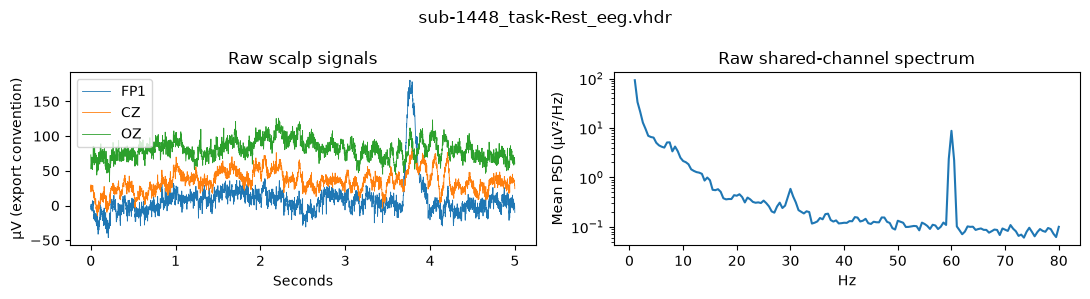

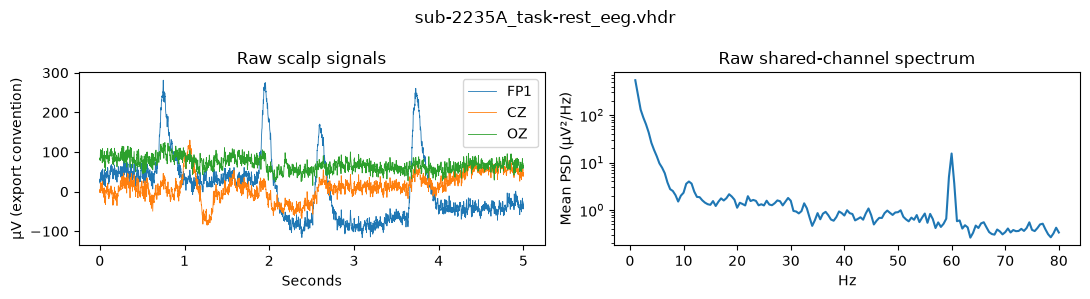

In [5]:
for dataset, example in examples.items():
    data, sfreq = example["data"], example["sfreq"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3))
    stop = min(data.shape[1], round(5 * sfreq))
    for channel in ["FP1", "CZ", "OZ"]:
        axes[0].plot(np.arange(stop)/sfreq, data[example["channels"].index(channel), :stop]*1e6,
                     label=channel, linewidth=0.6)
    axes[0].set(xlabel="Seconds", ylabel="µV (export convention)", title="Raw scalp signals")
    axes[0].legend()
    frequencies, psd = welch(data, fs=sfreq, window="hann", nperseg=round(2*sfreq),
                            noverlap=round(sfreq), detrend="constant", axis=-1)
    use = (frequencies >= 1) & (frequencies <= 80)
    axes[1].semilogy(frequencies[use], psd[:, use].mean(axis=0)*1e12)
    axes[1].set(xlabel="Hz", ylabel="Mean PSD (µV²/Hz)", title="Raw shared-channel spectrum")
    fig.suptitle(example["recording_id"].split("/")[-1])
    fig.tight_layout()
    fig.savefig(OUTPUT / f"{dataset}_representative_raw.png", dpi=150)
    plt.show()
    plt.close(fig)

## 5. Consistent preprocessing
Use at most the first 300 seconds for each recording, to avoid using extra time in longer exports. The local files do not document an existing software filter, so apply a broad 0.5–40 Hz, fourth-order Butterworth filter with forward/backward zero-phase filtering. This leaves margins around the 1–30 Hz features. It does not undo unknown acquisition filters. A separate 60 Hz notch is unnecessary for these features after low-pass filtering.

Resample to 200 Hz using MNE's anti-aliased FFT resampling. Trim two seconds from each end, then create nonoverlapping 4-second epochs. Screen amplitude/flatness before re-referencing and again after average-referencing over the same shared channels. This avoids hiding a common artifact through subtraction. Bad annotated intervals are rejected by MNE if present. Exclude a recording with fewer than 15 accepted epochs (60 seconds); do not relax rules. Keep epoch onset/rejection logs and usable duration. All retained recordings use the identical channel list.

**Isolated bad-channel omission (revision 2).** A diagnosis-blind investigation of the original run (`outputs/exclusion_investigation`) found that almost all lost epochs failed the high-amplitude rule *before* referencing, and that a few recordings were lost to a single channel that failed in nearly every epoch while being unrelated to every other channel. Before screening, a channel is classed as isolated-bad when, over all candidate epochs before referencing, it (1) exceeds 200 µV in at least 90% of epochs, (2) has a median peak-to-peak amplitude at least 5× the median across channels, and (3) has an absolute correlation below 0.4 with every other channel over the continuous preprocessed recording. If exactly one channel qualifies it is omitted from the average reference, the epoch screen, and the channel-averaged features (48 channels remain). If more than one qualifies, none is omitted. Channels are not interpolated because no electrode coordinates are supplied. The amplitude thresholds, 60-second minimum, and bands are unchanged. Widespread frontal transients that correlate across channels (consistent with eye artifacts) are not affected by this rule. An exploratory ocular-ICA pilot was not adopted because its fits did not converge and the auxiliary EOG mapping is unresolved.

Rejections are now logged separately as high-amplitude or flat, before or after referencing, with offending channels. The original 49-channel outcome is recomputed alongside for comparison; it does not affect inclusion.

The provisional export interpretation is sufficient for reproducible technical processing here, but remains a scientific limitation for later analyses. No diagnosis enters the processing function.

In [6]:
def amplitude_failures(data):
    """Peak-to-peak high/flat failures per (epoch, channel) for data in volts."""
    ptp = np.ptp(data, axis=-1) * 1e6
    return ptp > SETTINGS["reject_peak_to_peak_uv"], ptp < SETTINGS["reject_flat_peak_to_peak_uv"]


def find_isolated_bad_channels(continuous, data, names):
    """Channels that fail nearly every epoch, are much larger than typical, and match no other channel."""
    rule = SETTINGS["isolated_bad_channel_rule"]
    high, _ = amplitude_failures(data)
    channel_median = np.median(np.ptp(data, axis=-1), axis=0)
    correlation = np.abs(np.corrcoef(continuous))
    np.fill_diagonal(correlation, 0)
    bad = ((high.mean(axis=0) >= rule["minimum_failed_epoch_fraction"])
           & (channel_median >= rule["minimum_ratio_to_median_channel_peak_to_peak"] * np.median(channel_median))
           & (correlation.max(axis=1) < rule["maximum_absolute_correlation_with_any_channel"]))
    return [names[i] for i in np.flatnonzero(bad)]


def screen_epochs(data):
    """Fixed screen before average referencing, then again after it on epochs that passed."""
    pre_high, pre_flat = amplitude_failures(data)
    pre_ok = ~(pre_high | pre_flat).any(axis=1)
    referenced = data - data.mean(axis=1, keepdims=True)
    post_high, post_flat = amplitude_failures(referenced)
    post_high &= pre_ok[:, None]
    post_flat &= pre_ok[:, None]
    kept = pre_ok & ~(post_high | post_flat).any(axis=1)
    return kept, referenced, (pre_high, pre_flat, post_high, post_flat)


def preprocess_recording(row):
    raw = read_recording(row)
    raw.crop(tmax=min(raw.times[-1], SETTINGS["maximum_input_seconds"] - 1/raw.info["sfreq"]))
    raw.load_data()
    raw.filter(*SETTINGS["filter_hz"], method="iir", phase="zero",
               iir_params={"order": 4, "ftype": "butter", "output": "sos"}, verbose=False)
    raw.resample(SETTINGS["sampling_hz"], method="fft", verbose=False)
    trim = SETTINGS["edge_trim_seconds"]
    raw.crop(tmin=trim, tmax=raw.times[-1]-trim)
    epochs = mne.make_fixed_length_epochs(raw, duration=SETTINGS["epoch_seconds"],
                                          preload=True, reject_by_annotation=True, verbose=False)
    annotation = {i: ";".join(reason) for i, reason in enumerate(epochs.drop_log) if reason}
    data, names = epochs.get_data(copy=False), epochs.ch_names
    candidates = find_isolated_bad_channels(raw.get_data(), data, names) if len(data) else []
    omitted = candidates if len(candidates) <= SETTINGS["isolated_bad_channel_rule"]["maximum_channels_omitted"] else []
    keep = [i for i, name in enumerate(names) if name not in omitted]
    channels = np.array(names)[keep]
    baseline_kept, _, _ = screen_epochs(data)  # original 49-channel rule, for comparison only
    kept, referenced, (pre_high, pre_flat, post_high, post_flat) = screen_epochs(data[:, keep])

    epoch_log, row_of = [], {epoch: i for i, epoch in enumerate(epochs.selection)}
    for epoch in range(len(epochs.drop_log)):
        entry = {"recording_id": row["recording_id"], "epoch_index": epoch,
                 "onset_seconds": trim + epoch*SETTINGS["epoch_seconds"],
                 "annotation": annotation.get(epoch, ""), "kept": False, "rejection_stage": "annotation",
                 "pre_reference_high_channels": "", "pre_reference_flat_channels": "",
                 "post_reference_high_channels": "", "post_reference_flat_channels": ""}
        i = row_of.get(epoch)
        if i is not None:
            entry.update(kept=bool(kept[i]),
                pre_reference_high_channels=";".join(channels[pre_high[i]]),
                pre_reference_flat_channels=";".join(channels[pre_flat[i]]),
                post_reference_high_channels=";".join(channels[post_high[i]]),
                post_reference_flat_channels=";".join(channels[post_flat[i]]))
            pre_failed = (pre_high[i] | pre_flat[i]).any()
            entry["rejection_stage"] = "" if kept[i] else "before_reference" if pre_failed else "after_reference"
        stage = {"annotation": [entry["annotation"]],
                 "before_reference": [entry["pre_reference_high_channels"], entry["pre_reference_flat_channels"]],
                 "after_reference": [entry["post_reference_high_channels"], entry["post_reference_flat_channels"]]}
        entry["rejection_channels_or_annotation"] = ";".join(x for x in stage.get(entry["rejection_stage"], []) if x)
        epoch_log.append(entry)

    pre_ok = ~(pre_high | pre_flat).any(axis=1)
    result = {"total_epochs": len(epochs.drop_log), "annotation_rejected_epochs": len(annotation),
              "pre_reference_high_failed": int(pre_high.any(axis=1).sum()),
              "pre_reference_flat_failed": int(pre_flat.any(axis=1).sum()),
              "post_reference_candidates": int(pre_ok.sum()),
              "post_reference_high_failed": int(post_high.any(axis=1).sum()),
              "post_reference_flat_failed": int(post_flat.any(axis=1).sum()),
              "retained_epochs": int(kept.sum()), "usable_seconds": int(kept.sum())*SETTINGS["epoch_seconds"],
              "isolated_bad_channel_candidates": ";".join(candidates), "omitted_channel": ";".join(omitted),
              "retained_channels": ";".join(channels), "n_retained_channels": len(channels),
              "baseline_49ch_retained_epochs": int(baseline_kept.sum()),
              "baseline_49ch_usable_seconds": int(baseline_kept.sum())*SETTINGS["epoch_seconds"],
              "processing_reason": ""}
    spectrum, example = None, None
    if result["usable_seconds"] < SETTINGS["minimum_usable_seconds"]:
        result["processing_reason"] = "fewer than 60 usable seconds after fixed artifact rejection"
    else:
        frequencies, psd = welch(referenced[kept], fs=SETTINGS["sampling_hz"], window="hann",
            nperseg=round(SETTINGS["welch_window_seconds"]*SETTINGS["sampling_hz"]),
            noverlap=round(SETTINGS["welch_window_seconds"]*SETTINGS["sampling_hz"]*SETTINGS["welch_overlap_fraction"]),
            detrend="constant", scaling="density", average="mean", axis=-1)
        spectrum = (frequencies, psd.mean(axis=0))  # Average epochs first, preserving channels.
    if omitted:
        bad = names.index(omitted[0])
        worst = int(np.argmax(np.ptp(data[:, bad], axis=-1)))
        example = {"names": names, "omitted": omitted[0], "epoch": data[worst],
                   "onset": trim + epochs.selection[worst]*SETTINGS["epoch_seconds"],
                   "channel_median_ptp_uv": np.median(np.ptp(data, axis=-1), axis=0)*1e6,
                   "spectrum": spectrum, "channels": list(channels)}
    raw.close()
    return result, epoch_log, spectrum, example


EPOCH_COLUMNS = ["recording_id", "epoch_index", "onset_seconds", "kept", "rejection_stage",
                 "rejection_channels_or_annotation", "annotation", "pre_reference_high_channels",
                 "pre_reference_flat_channels", "post_reference_high_channels", "post_reference_flat_channels"]
COUNT_COLUMNS = ["total_epochs", "annotation_rejected_epochs", "pre_reference_high_failed",
                 "pre_reference_flat_failed", "post_reference_candidates", "post_reference_high_failed",
                 "post_reference_flat_failed", "retained_epochs", "n_retained_channels",
                 "baseline_49ch_retained_epochs"]
processing_rows, epoch_rows, spectra, cleaning_examples = [], [], {}, {}
participant_lookup = participant_inventory.set_index(["dataset", "participant_id"])
for row in inventory.to_dict("records"):
    participant = participant_lookup.loc[(row["dataset"], row["participant_id"])]
    reasons = global_blockers.copy()
    if participant.roster_rows != 1: reasons.append("missing or duplicate participant roster row")
    if row["diagnosis"] not in LABELS: reasons.append("unknown diagnosis label")
    if participant.n_recordings != 1: reasons.append("multiple recordings; aggregation decision required")
    if row["raw_qc_reason"]: reasons.append(row["raw_qc_reason"])
    if row["duplicate_binary"]: reasons.append("identical binary appears in multiple recordings")
    if row.get("software_filters") != "n/a": reasons.append("documented filter differs; review before re-filtering")
    result = {"recording_id": row["recording_id"], **{column: 0 for column in COUNT_COLUMNS},
              "usable_seconds": 0.0, "baseline_49ch_usable_seconds": 0.0, "retained_channels": "",
              "isolated_bad_channel_candidates": "", "omitted_channel": "",
              "processing_reason": "; ".join(reasons)}
    processed = False
    if not reasons:
        try:
            output, log, spectrum, example = preprocess_recording(row)
            result.update(output)
            epoch_rows.extend(log)
            processed = True
            if spectrum is not None:
                spectra[row["recording_id"]] = spectrum
            if example is not None:
                cleaning_examples[row["recording_id"]] = example
        except (OSError, ValueError, RuntimeError) as error:
            result["processing_reason"] = f"processing failed: {type(error).__name__}: {error}"
    result["included"] = result["processing_reason"] == ""
    result["baseline_49ch_included"] = processed and result["baseline_49ch_usable_seconds"] >= SETTINGS["minimum_usable_seconds"]
    processing_rows.append(result)
    if len(processing_rows) % 20 == 0:
        print(f"Processed {len(processing_rows)} / {len(inventory)} recordings")
recording_qc = inventory.merge(pd.DataFrame(processing_rows), on="recording_id", validate="one_to_one")
epoch_qc = pd.DataFrame(epoch_rows, columns=EPOCH_COLUMNS)
participant_rows = []
for participant in participant_inventory.to_dict("records"):
    runs = recording_qc.loc[(recording_qc.dataset == participant["dataset"]) &
                            (recording_qc.participant_id == participant["participant_id"])]
    included = len(runs) == 1 and bool(runs.iloc[0].included)
    reasons = sorted(set(runs.processing_reason) - {""}) if len(runs) else ["no recording found"]
    participant_rows.append({**participant, "included": included,
        "exclusion_reason": "; ".join(reasons),
        "usable_seconds": float(runs.usable_seconds.sum()),
        "retained_epochs": int(runs.retained_epochs.sum()),
        "n_retained_channels": int(runs.n_retained_channels.min()) if len(runs) else 0,
        "retained_channels": runs.iloc[0].retained_channels if len(runs) == 1 else "",
        "omitted_channel": runs.iloc[0].omitted_channel if len(runs) == 1 else "",
        "baseline_49ch_included": len(runs) == 1 and bool(runs.iloc[0].baseline_49ch_included),
        "baseline_49ch_usable_seconds": float(runs.baseline_49ch_usable_seconds.sum()),
        "recording_ids": ";".join(runs.recording_id)})
participant_qc = pd.DataFrame(participant_rows)
display(participant_qc.groupby(["dataset", "included"]).size().rename("participants").to_frame())
display(participant_qc.loc[~participant_qc.included,
                          ["dataset", "participant_id", "usable_seconds", "exclusion_reason"]])


Processed 20 / 143 recordings


Processed 40 / 143 recordings


Processed 60 / 143 recordings


Processed 80 / 143 recordings


Processed 100 / 143 recordings


Processed 120 / 143 recordings


Processed 140 / 143 recordings


participants
dataset        included              
resting-task-1 False                7
               True                75
resting-task-2 False               26
               True                35

,dataset,participant_id,usable_seconds,exclusion_reason
10,resting-task-1,sub-2009,48.0,fewer than 60 usable seconds after fixed artifact rejection
14,resting-task-1,sub-2020,24.0,fewer than 60 usable seconds after fixed artifact rejection
17,resting-task-1,sub-2034,24.0,fewer than 60 usable seconds after fixed artifact rejection
40,resting-task-1,sub-2124,28.0,fewer than 60 usable seconds after fixed artifact rejection
64,resting-task-1,sub-2178,36.0,fewer than 60 usable seconds after fixed artifact rejection
77,resting-task-1,sub-2218,4.0,fewer than 60 usable seconds after fixed artifact rejection
78,resting-task-1,sub-2221,40.0,fewer than 60 usable seconds after fixed artifact rejection
82,resting-task-2,sub-2235A,32.0,fewer than 60 usable seconds after fixed artifact rejection
85,resting-task-2,sub-2240A,32.0,fewer than 60 usable seconds after fixed artifact rejection
89,resting-task-2,sub-2252A,8.0,fewer than 60 usable seconds after fixed artifact rejection


In [7]:
# Rejection causes by dataset, stage, and rule (diagnosis-blind). An epoch can fail
# high and flat on different channels, so rule counts may overlap within a stage.
stage_summary = recording_qc.groupby("dataset")[COUNT_COLUMNS[:-2] + ["baseline_49ch_retained_epochs"]].sum()
display(stage_summary)
dataset_of = recording_qc.set_index("recording_id").dataset
channel_counts = []
for column in ["pre_reference_high_channels", "pre_reference_flat_channels",
               "post_reference_high_channels", "post_reference_flat_channels"]:
    stage, rule = column.removesuffix("_channels").rsplit("_", 1)
    failures = epoch_qc[["recording_id", column]].assign(channel=epoch_qc[column].str.split(";")).explode("channel")
    failures = failures.loc[failures.channel.ne("")]
    counts = failures.groupby([failures.recording_id.map(dataset_of), "channel"]).size()
    channel_counts.append(counts.rename("failed_epochs").reset_index().assign(stage=stage, rule=rule))
channel_summary = (pd.concat(channel_counts, ignore_index=True)
                   .rename(columns={"recording_id": "dataset"})
                   [["dataset", "stage", "rule", "channel", "failed_epochs"]]
                   .sort_values(["dataset", "stage", "rule", "failed_epochs"], ascending=[True, True, True, False]))
for dataset in DATASETS:
    top = channel_summary.loc[(channel_summary.dataset == dataset) & (channel_summary.stage == "pre_reference")
                              & (channel_summary.rule == "high")].head(10)
    print(dataset, "- channels most often above 200 µV before referencing (epochs; a single epoch can name several):")
    print(", ".join(f"{r.channel}: {r.failed_epochs}" for r in top.itertuples()))
comparison = pd.crosstab([participant_qc.dataset, participant_qc.baseline_49ch_included.rename("baseline_49ch_included")],
                         participant_qc.included.rename("revised_included"))
display(comparison)
display(recording_qc.loc[recording_qc.isolated_bad_channel_candidates.ne(""),
                         ["dataset", "participant_id", "isolated_bad_channel_candidates", "omitted_channel",
                          "baseline_49ch_usable_seconds", "usable_seconds", "included"]])


,total_epochs,annotation_rejected_epochs,pre_reference_high_failed,pre_reference_flat_failed,post_reference_candidates,post_reference_high_failed,post_reference_flat_failed,retained_epochs,baseline_49ch_retained_epochs
dataset,,,,,,,,,
resting-task-1,6068,0,1901,10,4158,3,2,4153,4083
resting-task-2,4514,0,2559,0,1955,3,0,1952,1861


resting-task-1 - channels most often above 200 µV before referencing (epochs; a single epoch can name several):
FP2: 1515, FP1: 1269, AF7: 593, AF4: 386, AF3: 336, F1: 139, F8: 134, F6: 133, O2: 121, O1: 120
resting-task-2 - channels most often above 200 µV before referencing (epochs; a single epoch can name several):
FP1: 2208, FP2: 1993, AF7: 1636, AF3: 943, AF4: 853, F6: 327, F8: 283, F5: 271, F7: 247, P4: 220


revised_included                       False  True 
dataset        baseline_49ch_included              
resting-task-1 False                       7      1
               True                        0     74
resting-task-2 False                      26      2
               True                        0     33

,dataset,participant_id,isolated_bad_channel_candidates,omitted_channel,baseline_49ch_usable_seconds,usable_seconds,included
11,resting-task-1,sub-2015,FP1,FP1,0.0,280.0,True
119,resting-task-2,sub-2426A,F3,F3,0.0,0.0,False
121,resting-task-2,sub-2431A,F3,F3,0.0,228.0,True
133,resting-task-2,sub-2505A,AF7,AF7,12.0,148.0,True


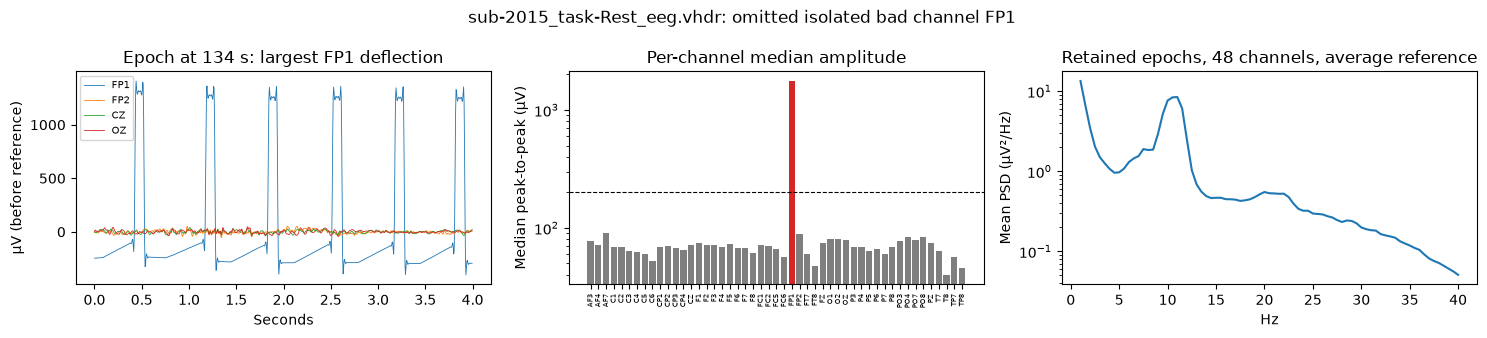

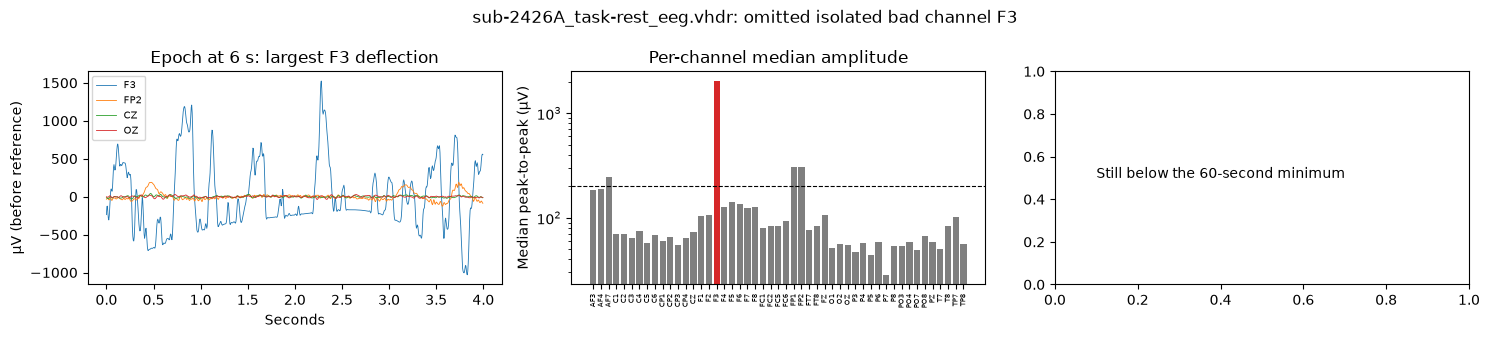

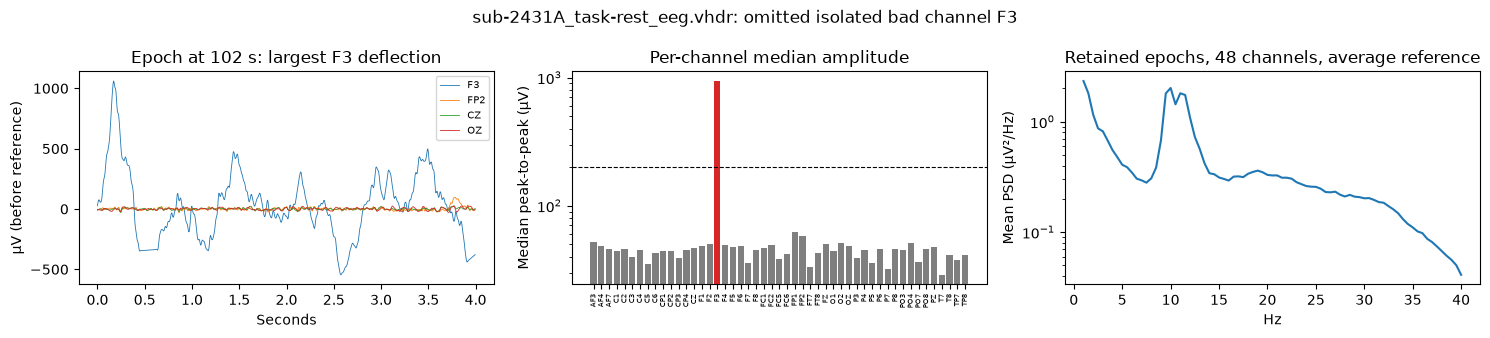

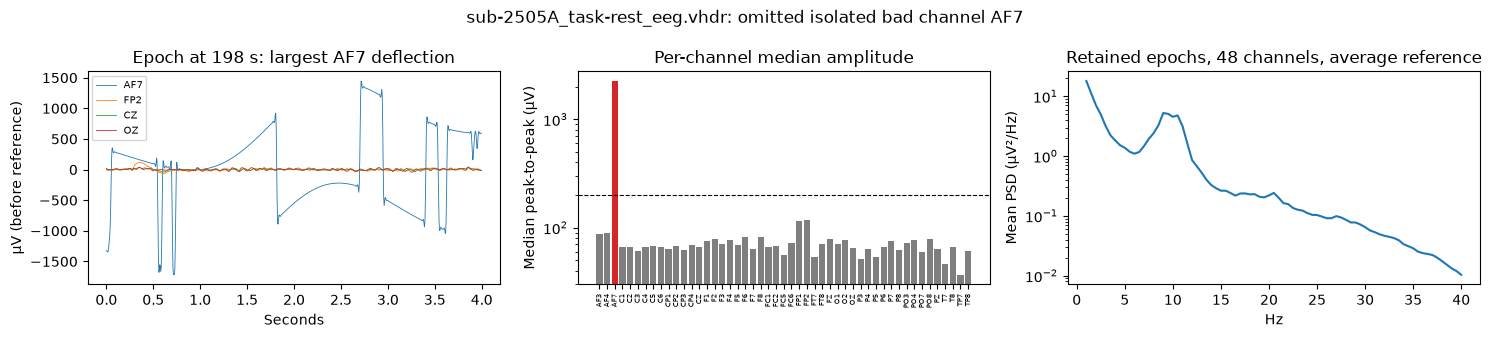

In [8]:
# Representative cleaning plots: every recording whose isolated bad channel was omitted.
for recording_id, example in cleaning_examples.items():
    names, bad = example["names"], example["omitted"]
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
    t = np.arange(example["epoch"].shape[1]) / SETTINGS["sampling_hz"]
    for channel in dict.fromkeys([bad, "FP2", "CZ", "OZ"]):
        axes[0].plot(t, example["epoch"][names.index(channel)]*1e6, label=channel, linewidth=0.6)
    axes[0].set(xlabel="Seconds", ylabel="µV (before reference)",
                title=f"Epoch at {example['onset']:.0f} s: largest {bad} deflection")
    axes[0].legend(fontsize=7)
    colors = ["tab:red" if name == bad else "tab:gray" for name in names]
    axes[1].bar(range(len(names)), example["channel_median_ptp_uv"], color=colors)
    axes[1].axhline(SETTINGS["reject_peak_to_peak_uv"], color="k", linestyle="--", linewidth=0.8)
    axes[1].set_xticks(range(len(names)), names, rotation=90, fontsize=5)
    axes[1].set(ylabel="Median peak-to-peak (µV)", yscale="log", title="Per-channel median amplitude")
    if example["spectrum"] is not None:
        frequencies, psd = example["spectrum"]
        use = (frequencies >= 1) & (frequencies <= 40)
        axes[2].semilogy(frequencies[use], psd[:, use].mean(axis=0)*1e12)
        axes[2].set(xlabel="Hz", ylabel="Mean PSD (µV²/Hz)",
                    title=f"Retained epochs, {len(example['channels'])} channels, average reference")
    else:
        axes[2].text(0.1, 0.5, "Still below the 60-second minimum")
    fig.suptitle(f"{recording_id.split('/')[-1]}: omitted isolated bad channel {bad}")
    fig.tight_layout()
    fig.savefig(OUTPUT / f"cleaning_{recording_id.split('/')[1]}_{recording_id.split('/')[2]}.png", dpi=130)
    plt.show()
    plt.close(fig)


## 6. Feature extraction
Each accepted 4-second epoch gets a Welch PSD using 2-second Hann windows, 50% overlap, constant detrending, and mean averaging. At 200 Hz this gives 0.5 Hz frequency bins. First average PSDs equally across accepted epochs **within each channel**. Sum PSD × bin width for each band, divide by that channel's 1–30 Hz total, then average the four relative powers equally across the retained channels (the 49 shared channels, or 48 when one isolated bad channel was omitted). Participants receive one row each, regardless of how many epochs survived.

Bands are delta **[1, 4)**, theta **[4, 8)**, alpha **[8, 13)**, and beta **[13, 30]** Hz. The denominator includes all bins from 1 through 30 Hz. These disjoint bin definitions partition the denominator, so the four features sum to one (up to rounding). Units cancel in relative power, but amplitude rejection still depends on the export unit convention. No feature scaling, selection, or group comparison is performed.

In [9]:
FEATURES = ["relative_delta", "relative_theta", "relative_alpha", "relative_beta"]
feature_rows = []
for row in recording_qc.loc[recording_qc.included].to_dict("records"):
    frequencies, channel_psd = spectra[row["recording_id"]]
    df = frequencies[1] - frequencies[0]
    total_bins = (frequencies >= 1) & (frequencies <= 30)
    total_power = channel_psd[:, total_bins].sum(axis=1) * df
    if not np.isfinite(channel_psd).all() or not (total_power > 0).all():
        raise ValueError(f"Invalid PSD or zero total power: {row['recording_id']}")
    features = {}
    for band, (low, high) in SETTINGS["bands_hz"].items():
        bins = (frequencies >= low) & ((frequencies <= high) if band == "beta" else (frequencies < high))
        band_power = channel_psd[:, bins].sum(axis=1) * df
        features[f"relative_{band}"] = float((band_power / total_power).mean())
    feature_rows.append({key: row[key] for key in ["dataset", "accession", "participant_id", "diagnosis",
                         "acquisition", "recording_id", "sha256", "usable_seconds", "retained_epochs",
                         "n_retained_channels", "omitted_channel"]} | features | {"export_interpretation": "BIDS order / microvolt convention"})
feature_columns = ["dataset", "accession", "participant_id", "diagnosis", "acquisition", *FEATURES,
                   "recording_id", "sha256", "usable_seconds", "retained_epochs", "n_retained_channels",
                   "omitted_channel", "export_interpretation"]
features = pd.DataFrame(feature_rows, columns=feature_columns)
print("Participant feature rows:", len(features))
# Do not inspect diagnosis-related feature patterns in this foundation notebook.
display(features.groupby("dataset").size().rename("feature_rows").to_frame())

Participant feature rows: 110


,feature_rows
dataset,
resting-task-1,75
resting-task-2,35


## 7. Validation and saved outputs
Validate unique participant rows, feature ranges and sums, finite values, minimum usable duration, shared channels, and exact agreement with the inclusion inventory. Empty tables are valid file formats but never count as an analysis-ready dataset. Save both dataset tables separately, plus recording/participant/epoch provenance, settings, and a short report. Re-running overwrites these named derived outputs so excluded participants do not leave stale feature rows.

Technical validation is conditional on the stated export conventions. It does not establish person-level cohort independence or recover undocumented filtering/annotation history.

In [10]:
assert not participant_qc.duplicated(["dataset", "participant_id"]).any()
assert not features.duplicated(["dataset", "participant_id"]).any()
assert not features.participant_id.duplicated().any(), "Participant IDs overlap between output datasets"
values = features[FEATURES].to_numpy(dtype=float)
assert np.isfinite(values).all()
assert ((values >= 0) & (values <= 1)).all()
assert np.allclose(values.sum(axis=1), 1, atol=1e-10)
expected = set(map(tuple, participant_qc.loc[participant_qc.included, ["dataset", "participant_id"]].to_numpy()))
actual = set(map(tuple, features[["dataset", "participant_id"]].to_numpy()))
assert actual == expected
assert features.usable_seconds.ge(SETTINGS["minimum_usable_seconds"]).all()
included_qc = recording_qc.loc[recording_qc.included]
assert included_qc.omitted_channel.map(lambda x: len([c for c in x.split(";") if c])).le(
    SETTINGS["isolated_bad_channel_rule"]["maximum_channels_omitted"]).all()
expected_channels = included_qc.omitted_channel.map(lambda x: ";".join(c for c in shared_channels if c != x))
assert included_qc.retained_channels.eq(expected_channels).all()
assert features.n_retained_channels.eq(len(shared_channels) - features.omitted_channel.ne("").astype(int)).all()
assert set(features.recording_id) == set(recording_qc.loc[recording_qc.included, "recording_id"])
assert participant_qc.loc[~participant_qc.included, "exclusion_reason"].ne("").all()
if len(epoch_qc):
    retained_counts = epoch_qc.groupby("recording_id").kept.sum()
    processed_qc = recording_qc.set_index("recording_id").loc[retained_counts.index]
    assert np.array_equal(processed_qc.retained_epochs.to_numpy(), retained_counts.to_numpy())
    stage_counts = epoch_qc.groupby("recording_id").rejection_stage.value_counts().unstack(fill_value=0)
    stage_counts = stage_counts.reindex(columns=["before_reference", "after_reference"], fill_value=0)
    assert np.array_equal((processed_qc.total_epochs - processed_qc.annotation_rejected_epochs
                           - processed_qc.post_reference_candidates).to_numpy(),
                          stage_counts.before_reference.loc[processed_qc.index].to_numpy())

for dataset in DATASETS:
    features.loc[features.dataset == dataset, feature_columns].to_csv(OUTPUT / f"{dataset}_features.csv", index=False)
participant_qc.to_csv(OUTPUT / "participant_qc.csv", index=False)
recording_qc.to_csv(OUTPUT / "recording_qc.csv", index=False)
participant_inventory.to_csv(OUTPUT / "participant_inventory.csv", index=False)
epoch_qc.to_csv(OUTPUT / "epoch_qc.csv", index=False)
stage_summary.to_csv(OUTPUT / "rejection_stage_summary.csv")
channel_summary.to_csv(OUTPUT / "rejection_channel_summary.csv", index=False)
placement.to_csv(OUTPUT / "transferred_participant_check.csv", index=False)
compatibility.to_csv(OUTPUT / "dataset_compatibility.csv")
settings_output = {**SETTINGS, "datasets": DATASETS,
    "versions": {p: version(p) for p in ["numpy", "pandas", "scipy", "matplotlib", "mne"]},
    "python": platform.python_version(),
    "feature_definition": "mean over retained channels of band/total from epoch-averaged Welch PSD; 0.5 Hz bin sums",
    "revision": "2: isolated bad-channel omission and staged high/flat rejection logging; thresholds unchanged",
    "unresolved": ["Person-level independence cannot be established from IDs and the READMEs alone",
                   "Channel order and scale follow BIDS/EEGLAB conventions, without original acquisition cross-check",
                   "Hardware filtering, complete processing history, and original artifact annotations unavailable",
                   "Widespread frontal transients consistent with eye artifacts remain the main cause of epoch loss; ocular ICA was evaluated but not adopted"]}
(OUTPUT / "preprocessing_settings.json").write_text(json.dumps(settings_output, indent=2) + "\n")

report = ["# Dataset check and preprocessing report", "",
          "Feature tables are technically validated under the documented export conventions.",
          "They are not proof of an independently verified external test cohort.", "",
          f"Shared scalp channels: {len(shared_channels)}.",
          f"Shared participant IDs: {overlap or 'none'}.",
          f"All ten transferred participants placed correctly: {bool(placement.correct_placement.all())}.",
          f"Identical binary files: {int(inventory.duplicate_binary.sum())} recordings.", ""]
for dataset in DATASETS:
    p = participant_qc.loc[participant_qc.dataset == dataset]
    r = recording_qc.loc[recording_qc.dataset == dataset]
    report.extend([f"## {dataset} ({DATASETS[dataset]['accession']} v1.0.1)",
        f"Participants inventoried: {len(p)}; feature rows: {int(p.included.sum())}; excluded: {int((~p.included).sum())}.",
        f"Original diagnostic counts: {p.diagnosis.value_counts().to_dict()}.",
        f"Retained diagnostic counts: {p.loc[p.included, 'diagnosis'].value_counts().to_dict()}.",
        f"Sampling rates (Hz): {sorted(r.sampling_hz.dropna().unique().tolist())}.",
        f"Raw duration range (s): {r.duration_seconds.min():.2f}–{r.duration_seconds.max():.2f}.",
        f"Exclusion reasons: {p.loc[~p.included, 'exclusion_reason'].value_counts().to_dict()}.",
        f"Original 49-channel rule would include: {int(p.baseline_49ch_included.sum())}.",
        f"Omitted isolated bad channels: {r.loc[r.omitted_channel.ne(''), ['participant_id', 'omitted_channel']].to_records(index=False).tolist() or 'none'}.",
        f"Epoch failures before referencing (high / flat): {int(r.pre_reference_high_failed.sum())} / {int(r.pre_reference_flat_failed.sum())}; "
        f"after referencing: {int(r.post_reference_high_failed.sum())} / {int(r.post_reference_flat_failed.sum())}.", ""])
report.extend(["## Remaining limitations", *[f"- {x}." for x in settings_output["unresolved"]], "",
               "The Task 1 transferred participants remain eligible; acquisition origin alone is not an exclusion.",
               "No ICA, interpolation, classifier, learned scaling, or diagnosis-based tuning was performed.",
               "At most one isolated bad channel per recording is omitted (not interpolated); see the settings file.", "",
               "## Readiness checklist",
               "- [x] Source data inspected without modification.",
               "- [x] Participant inventory and transferred-participant placement checked.",
               "- [x] Fixed processing, artifact rules, and feature definitions recorded.",
               "- [x] Output integrity and exact agreement with QC checked."])
nonempty = all((features.dataset == d).any() for d in DATASETS)
report.append(f"- [{'x' if nonempty else ' '}] Both datasets have accepted participant feature rows.")
report.extend(["- [ ] Independent person-level cohort membership confirmed beyond dataset IDs.",
               "- [ ] Original acquisition channel order/calibration and full processing history independently verified."])
if global_blockers:
    report.extend(["", "## Blocking file inconsistencies", *[f"- {x}" for x in global_blockers]])
(OUTPUT / "dataset_check_report.md").write_text("\n".join(report) + "\n")
display(Markdown("\n".join(report)))
print("Saved outputs:", OUTPUT)
print("Validation passed for", len(features), "feature rows.")
if not nonempty:
    print("NOT READY: at least one dataset has no usable participant features. See the QC reasons.")

# Dataset check and preprocessing report

Feature tables are technically validated under the documented export conventions.
They are not proof of an independently verified external test cohort.

Shared scalp channels: 49.
Shared participant IDs: none.
All ten transferred participants placed correctly: True.
Identical binary files: 0 recordings.

## resting-task-1 (ds003944 v1.0.1)
Participants inventoried: 82; feature rows: 75; excluded: 7.
Original diagnostic counts: {'Psychosis': 50, 'Control': 32}.
Retained diagnostic counts: {'Psychosis': 46, 'Control': 29}.
Sampling rates (Hz): [1000.0, 3000.0003000000297].
Raw duration range (s): 300.00–397.00.
Exclusion reasons: {'fewer than 60 usable seconds after fixed artifact rejection': 7}.
Original 49-channel rule would include: 74.
Omitted isolated bad channels: [('sub-2015', 'FP1')].
Epoch failures before referencing (high / flat): 1901 / 10; after referencing: 3 / 2.

## resting-task-2 (ds003947 v1.0.1)
Participants inventoried: 61; feature rows: 35; excluded: 26.
Original diagnostic counts: {'Psychosis': 31, 'Control': 30}.
Retained diagnostic counts: {'Psychosis': 21, 'Control': 14}.
Sampling rates (Hz): [1000.0, 3000.0003000000297].
Raw duration range (s): 300.00–368.50.
Exclusion reasons: {'fewer than 60 usable seconds after fixed artifact rejection': 26}.
Original 49-channel rule would include: 33.
Omitted isolated bad channels: [('sub-2426A', 'F3'), ('sub-2431A', 'F3'), ('sub-2505A', 'AF7')].
Epoch failures before referencing (high / flat): 2559 / 0; after referencing: 3 / 0.

## Remaining limitations
- Person-level independence cannot be established from IDs and the READMEs alone.
- Channel order and scale follow BIDS/EEGLAB conventions, without original acquisition cross-check.
- Hardware filtering, complete processing history, and original artifact annotations unavailable.
- Widespread frontal transients consistent with eye artifacts remain the main cause of epoch loss; ocular ICA was evaluated but not adopted.

The Task 1 transferred participants remain eligible; acquisition origin alone is not an exclusion.
No ICA, interpolation, classifier, learned scaling, or diagnosis-based tuning was performed.
At most one isolated bad channel per recording is omitted (not interpolated); see the settings file.

## Readiness checklist
- [x] Source data inspected without modification.
- [x] Participant inventory and transferred-participant placement checked.
- [x] Fixed processing, artifact rules, and feature definitions recorded.
- [x] Output integrity and exact agreement with QC checked.
- [x] Both datasets have accepted participant feature rows.
- [ ] Independent person-level cohort membership confirmed beyond dataset IDs.
- [ ] Original acquisition channel order/calibration and full processing history independently verified.

Saved outputs: /Users/akhil/Documents/nsci270-final/outputs/master_preprocessing
Validation passed for 110 feature rows.
